# 3. kNN: Predicting Heart Disease (same dataset as Section 2)

**Dataset documentation:** https://archive.ics.uci.edu/dataset/45/heart+disease
**Data file:** `data/heart.csv` - same cleaning and the same train/test split (`random_state=42`) as notebook 2, so the comparison is fair.

## 3.3 Modeling

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, recall_score, precision_score

os.makedirs('plots', exist_ok=True)
df = pd.read_csv('data/heart.csv').drop_duplicates().copy()
df['disease'] = 1 - df['target']          # in this file target=1 means HEALTHY (see notebook 2), so flip it
df = df.drop(columns='target')

X = df.drop(columns='disease')
y = df['disease']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (241, 13)  Test: (61, 13)


**Data preparation for kNN:** the same cleaning (duplicate removed, target flipped) and the same stratified 80/20 split with `random_state=42` as in notebook 2, so both models are tested on the identical 61 patients. Unlike trees, kNN uses distances, so features must be on a comparable scale and unordered category codes should not be treated as numbers.

In [2]:
# Scale numeric columns, one-hot encode the unordered categorical codes
numeric = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
nominal = ['cp', 'restecg', 'slope', 'thal']
binary = ['sex', 'fbs', 'exang']
prep = ColumnTransformer([('num', StandardScaler(), numeric),
                          ('cat', OneHotEncoder(handle_unknown='ignore'), nominal)],
                         remainder='passthrough')   # binary columns are already 0/1

def knn_pipe(k=5):
    return Pipeline([('prep', prep), ('knn', KNeighborsClassifier(n_neighbors=k))])

# Why scaling matters: kNN on raw features vs scaled features (k=5)
raw = cross_val_score(KNeighborsClassifier(5), X_train, y_train, cv=5).mean()
scaled = cross_val_score(knn_pipe(5), X_train, y_train, cv=5).mean()
print(f'5-fold CV accuracy, k=5 -> raw features: {raw:.3f} | scaled + encoded: {scaled:.3f}')

5-fold CV accuracy, k=5 -> raw features: 0.639 | scaled + encoded: 0.842


**Comment:** scaling and encoding matter a great deal: CV accuracy at k = 5 jumps from 0.64 on raw features to 0.84. Without scaling, `chol` (values around 250) and `thalach` (around 150) dominate the distance while `oldpeak` or binary features have almost no influence. I standardise the numeric columns and one-hot encode the unordered codes (`cp`, `restecg`, `slope`, `thal`).

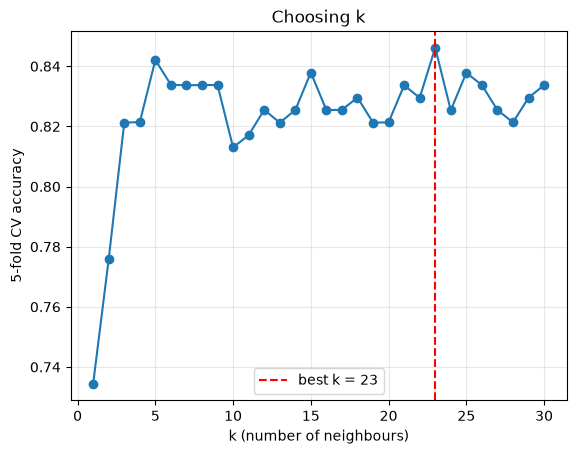

Best k: 23 | CV accuracy: 0.846


In [3]:
# Choose k with 5-fold cross validation
ks = range(1, 31)
cv_acc = [cross_val_score(knn_pipe(k), X_train, y_train, cv=5).mean() for k in ks]
best_k = list(ks)[int(np.argmax(cv_acc))]
plt.plot(list(ks), cv_acc, marker='o'); plt.axvline(best_k, color='r', ls='--', label=f'best k = {best_k}')
plt.xlabel('k (number of neighbours)'); plt.ylabel('5-fold CV accuracy'); plt.legend(); plt.grid(alpha=.3)
plt.title('Choosing k'); plt.savefig('plots/3_k_vs_cv.png', dpi=120); plt.show()
print('Best k:', best_k, '| CV accuracy:', round(max(cv_acc), 3))

**Comment:** k = 1 overfits badly (CV accuracy only about 0.73). Accuracy rises quickly up to k = 5 and then stays in a narrow band of roughly 0.81 to 0.85 for every larger k tried. The best CV accuracy is 0.846 at **k = 23**, but it is only marginally above k = 5 (0.842), so the exact choice matters little; I keep k = 23 because larger k gives a smoother, more stable boundary on this small, noisy dataset.

## 3.4 Evaluation & Comparison with Decision Tree

kNN test accuracy: 0.754
              precision    recall  f1-score   support

  No disease       0.76      0.79      0.78        33
     Disease       0.74      0.71      0.73        28

    accuracy                           0.75        61
   macro avg       0.75      0.75      0.75        61
weighted avg       0.75      0.75      0.75        61



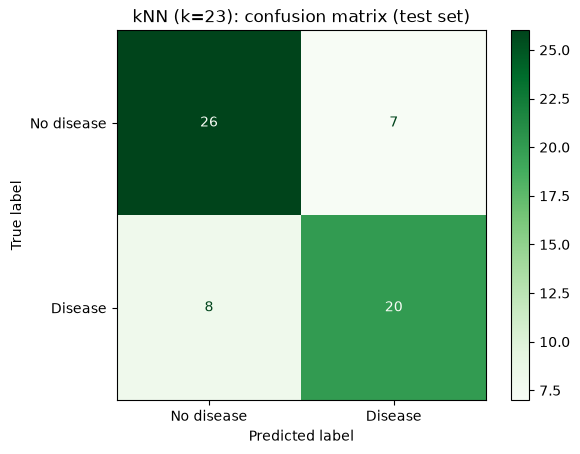

In [4]:
knn = knn_pipe(best_k).fit(X_train, y_train)
pred_knn = knn.predict(X_test)
print('kNN test accuracy:', round(accuracy_score(y_test, pred_knn), 3))
print(classification_report(y_test, pred_knn, target_names=['No disease', 'Disease']))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_knn), display_labels=['No disease', 'Disease']).plot(cmap='Greens')
plt.title(f'kNN (k={best_k}): confusion matrix (test set)'); plt.savefig('plots/3_confusion_matrix.png', dpi=120); plt.show()

In [5]:
# Re-fit the tuned decision tree from notebook 2 on the identical split
grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                    {'max_depth': range(1, 11), 'min_samples_leaf': [1, 3, 5, 10]}, cv=5).fit(X_train, y_train)
tree = grid.best_estimator_
pred_tree = tree.predict(X_test)

rows = {}
for name, model, pred in [('Decision tree', tree, pred_tree), (f'kNN (k={best_k})', knn, pred_knn)]:
    rows[name] = {'CV accuracy (train)': cross_val_score(model, X_train, y_train, cv=10).mean(),
                  'Test accuracy': accuracy_score(y_test, pred),
                  'Test precision (disease)': precision_score(y_test, pred),
                  'Test recall (disease)': recall_score(y_test, pred),
                  'Missed cases (FN)': int(((pred == 0) & (y_test == 1)).sum())}
print('Tree params:', grid.best_params_)
pd.DataFrame(rows).T.round(3)

Tree params: {'max_depth': 4, 'min_samples_leaf': 5}


,CV accuracy (train),Test accuracy,Test precision (disease),Test recall (disease),Missed cases (FN)
Decision tree,0.776,0.738,0.773,0.607,11.0
kNN (k=23),0.817,0.754,0.741,0.714,8.0


### Evaluation and comparison
| | Decision tree | kNN (k = 23) |
|---|---|---|
| 10-fold CV accuracy (train) | 0.776 | **0.817** |
| Test accuracy | 0.738 | **0.754** |
| Test precision (disease) | **0.773** | 0.741 |
| Test recall (disease) | 0.607 | **0.714** |
| Missed cases (false negatives) | 11 | **8** |

### Conclusion
kNN is slightly better on both cross-validation (+4 points) and the test set (+1.6 points, which is just one patient out of 61 and therefore not conclusive on its own). The practical difference is **recall**: kNN misses 8 sick patients instead of 11, which matters for a screening task. The tree has slightly higher precision, and its big advantage is **interpretability**: a clinician can read its rules, while kNN gives no explanation and needs the whole training set at prediction time. Neither model reaches high enough recall (best 71%) for unsupervised clinical use.

**Recommendation:** use kNN if the priority is catching as many cases as possible; use the tree if explaining each decision is more important. Both would likely improve with more data, an ensemble such as a random forest, or lowering the decision threshold to trade precision for recall.